# NSL-KDD: Feature Engineering and Modelling

This notebook presents the final pipeline and how it was chosen. Training is in `src/train.py`, which saves models and
out-of-fold and test predictions. This notebook loads those results so it runs in seconds.

**Ground rule: `KDDTest+` and `KDDTest-21` are never used to make a decision.** Every choice (features, models,
thresholds, two-stage design) is made on the training set with cross-validation. The test sets are only reported.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix, classification_report,
                             f1_score, accuracy_score, ConfusionMatrixDisplay)
from src.data import load_all, CLASSES
from src.features import NSLFeatureEngineer

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
FIG = "../reports/figures/"
train, test, test21 = load_all()
P = np.load("../reports/predictions.npz")
M = json.load(open("../reports/metrics.json"))
bin_det = joblib.load("../models/binary_detector.joblib")
mc_det = joblib.load("../models/multiclass_detector.joblib")
y, yt, y21 = train.is_attack.values, test.is_attack.values, test21.is_attack.values
THR = M["binary"]["threshold"]
print(f"Binary decision threshold (tuned on CV): {THR:.4f}")

Binary decision threshold (tuned on CV): 0.0100


## 1. Validation strategy: why random CV misleads here

The EDA showed that 17% of `KDDTest+` consists of **attack types that never appear in training**. A random K-fold split puts
every attack type into both the train and validation folds, so it measures *memorisation of known attacks*.

So I use **leave-attack-type-out CV**: each attack type (e.g. `neptune`, `guess_passwd`) sits entirely in one fold.
Every validation fold then contains attacks the model has never seen, like the real test set.

,accuracy,f1,recall,roc_auc
Random 3-fold CV (LightGBM),0.9988,0.9988,0.9983,1.0000
Leave-attack-out CV,0.9296,0.9183,0.8494,0.9984
KDDTest+ (held out),0.7934,0.7839,0.6581,0.9674


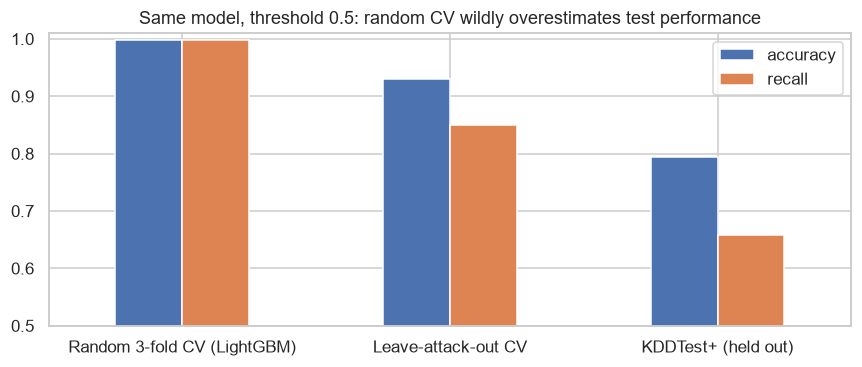

In [2]:
b = M["binary"]
rows = {"Random 3-fold CV (LightGBM)": b["cv_random@0.5"], "Leave-attack-out CV": b["cv_leave_attack_out@0.5"],
        "KDDTest+ (held out)": b["test+@0.5"]}
cmp = pd.DataFrame(rows).T[["accuracy", "f1", "recall", "roc_auc"]]
display(cmp.round(4))
ax = cmp[["accuracy", "recall"]].plot.bar(figsize=(8, 3.5), ylim=(0.5, 1.01), rot=0)
ax.set_title("Same model, threshold 0.5: random CV wildly overestimates test performance")
plt.tight_layout(); plt.savefig(FIG + "validation_strategy.png", bbox_inches="tight"); plt.show()

## 2. Feature engineering

All transforms are stateless or fitted inside the pipeline, so nothing leaks across CV folds.

| Group | Features | Rationale (from EDA) |
|---|---|---|
| Dropped | `num_outbound_cmds` | constant |
| Log transform | 16 heavy-tailed counts/volumes (`src_bytes`, `dst_bytes`, `duration`, `count`, ...) | skew up to 350 |
| Volume/direction | `total_bytes`, `src_dst_ratio`, `no_payload`, `bytes_per_sec` | bytes are the top MI features. Scans/DoS carry no payload |
| Error aggregates | `serror_total`, `rerror_total` | 4 near-duplicate rates each (r > 0.9). SYN floods vs rejected probes |
| Service concentration | `srv_count_ratio`, `dst_host_srv_ratio` | DoS hits one service, probes spread across many |
| Host-intrusion | `intrusion_signals`, `root_activity` | R2L/U2R live in rare content features. Pooling them helps the minority classes |
| Flag groups | `flag_is_sf`, `flag_half_open`, `flag_rejected` | `flag` separates DoS (S0) and Probe (REJ/RSTR) cleanly |
| Categorical | one-hot of `protocol_type`, `service`, `flag`. Services with < 20 rows are grouped as *infrequent* | 70 services, many rare |

In [3]:
Xfe = NSLFeatureEngineer().transform(train.head(3))
new = [c for c in Xfe.columns if c not in train.columns]
print(f"{len(new)} engineered features:", new)
print(f"Model input width after one-hot: {len(bin_det.feature_names_)} columns")

13 engineered features: ['total_bytes', 'src_dst_ratio', 'no_payload', 'bytes_per_sec', 'serror_total', 'rerror_total', 'srv_count_ratio', 'dst_host_srv_ratio', 'intrusion_signals', 'root_activity', 'flag_is_sf', 'flag_half_open', 'flag_rejected']
Model input width after one-hot: 126 columns


lao_cv_f1           test_auc           test_acc        
features           engineered     raw engineered     raw engineered     raw
model                                                                      
ExtraTrees             0.9267  0.8890     0.9585  0.9559     0.7849  0.7873
LightGBM               0.9146  0.9006     0.9655  0.9599     0.7808  0.7814
LogisticRegression     0.8846  0.8729     0.8040  0.7925     0.7411  0.7545
RandomForest           0.9066  0.8733     0.9650  0.9603     0.7826  0.7757
XGBoost                0.8986  0.8835     0.9689  0.9699     0.7937  0.7913

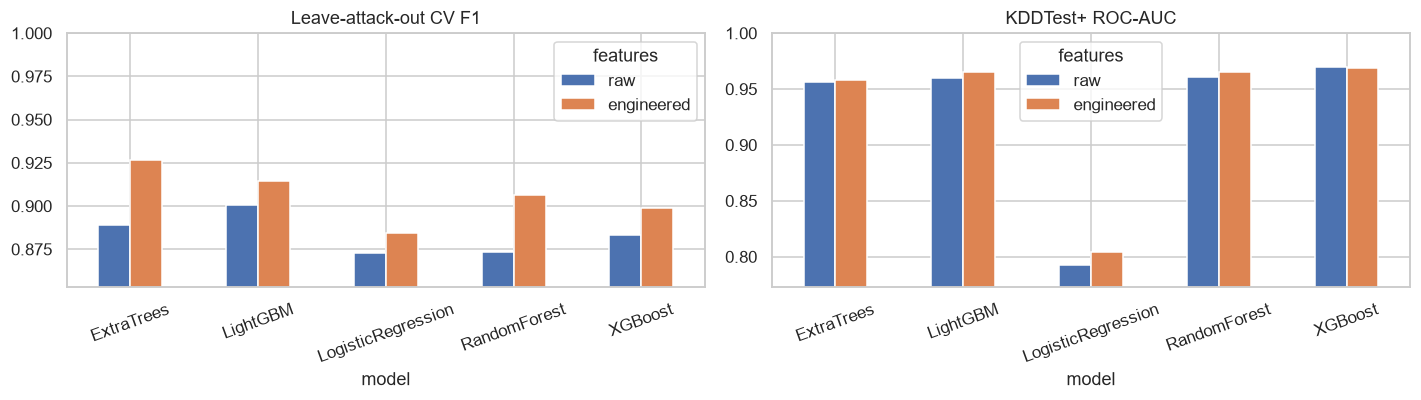

In [4]:
fc = pd.read_csv("../reports/feature_comparison.csv")
piv = fc.pivot(index="model", columns="features", values=["lao_cv_f1", "test_auc", "test_acc"])
display(piv.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, met, title in [(axes[0], "lao_cv_f1", "Leave-attack-out CV F1"), (axes[1], "test_auc", "KDDTest+ ROC-AUC")]:
    fc.pivot(index="model", columns="features", values=met)[["raw", "engineered"]].plot.bar(ax=ax, rot=20)
    lo = fc[met].min(); ax.set_ylim(lo - 0.02, 1.0); ax.set_title(title)
plt.tight_layout(); plt.savefig(FIG + "feature_engineering_gain.png", bbox_inches="tight"); plt.show()

**Reading the comparison:** engineered features improve leave-attack-out CV for every tree model
(ExtraTrees F1 0.889 → 0.927, RandomForest 0.873 → 0.907, LightGBM 0.901 → 0.915). On KDDTest+ the gains are small
(AUC +0.003 to +0.010 for most models). Tree ensembles already find most of this structure on their own, so the larger
lever on this dataset is the decision rule (section 4).

## 3. Which features matter

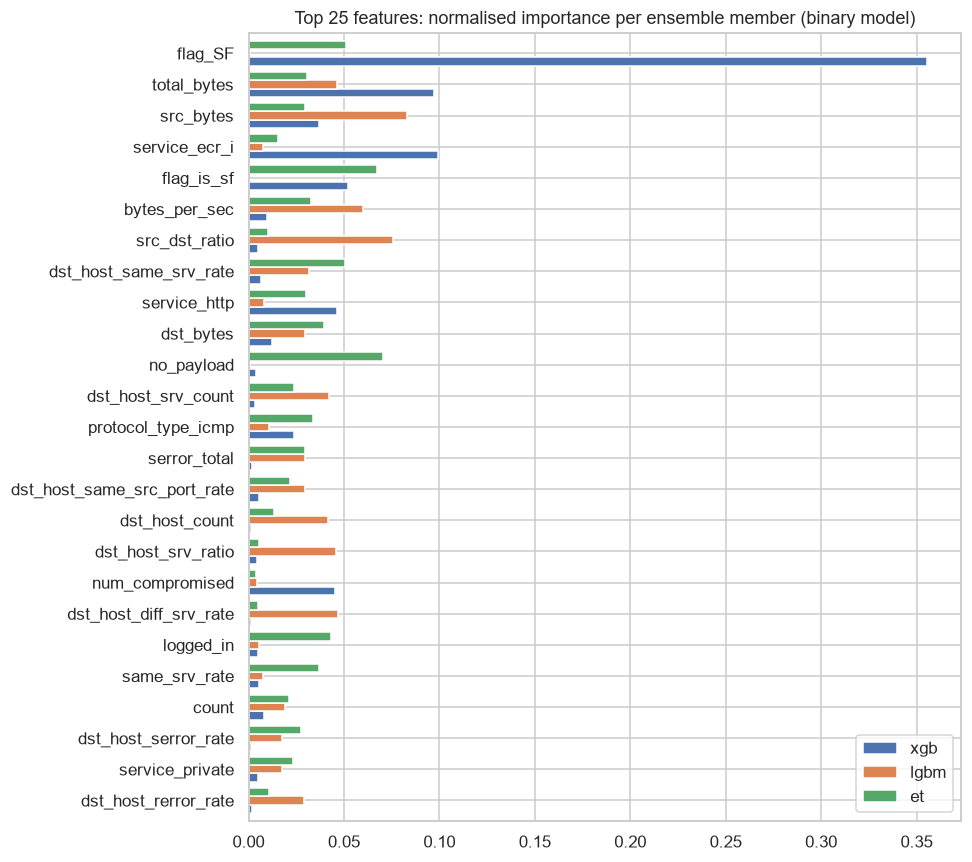

Engineered features in the top 25: ['total_bytes', 'flag_is_sf', 'bytes_per_sec', 'src_dst_ratio', 'no_payload', 'serror_total', 'dst_host_srv_ratio']


In [5]:
names = bin_det.feature_names_
imp = pd.DataFrame({n: m.feature_importances_ / m.feature_importances_.sum() for n, m in bin_det.models_.items()}, index=names)
imp["mean"] = imp.mean(axis=1)
top = imp.sort_values("mean", ascending=False).head(25)
fig, ax = plt.subplots(figsize=(9, 8))
top[["xgb", "lgbm", "et"]][::-1].plot.barh(ax=ax, width=0.8)
ax.set_title("Top 25 features: normalised importance per ensemble member (binary model)")
plt.tight_layout(); plt.savefig(FIG + "feature_importance.png", bbox_inches="tight"); plt.show()
eng = set(new) | {n for n in names if n.startswith(("flag_is", "flag_half", "flag_rej"))}
print("Engineered features in the top 25:", [n for n in top.index if n in eng])

## 4. Binary detector: normal vs attack

**Model:** soft-voting ensemble of three diverse, regularised learners on the engineered features:
- XGBoost (depth 6, column subsampling 0.5, L2 = 5)
- LightGBM (31 leaves, `min_child_samples` = 50, bagging)
- ExtraTrees (300 trees: randomised splits generalise better to unseen attacks)

### 4.1 Ranking quality (ROC-AUC)

,leave-attack-out CV,KDDTest+,KDDTest-21
xgb,0.9963,0.9714,0.8524
lgbm,0.9966,0.9713,0.8515
et,0.9979,0.9585,0.8000
ensemble,0.9984,0.9674,0.8216


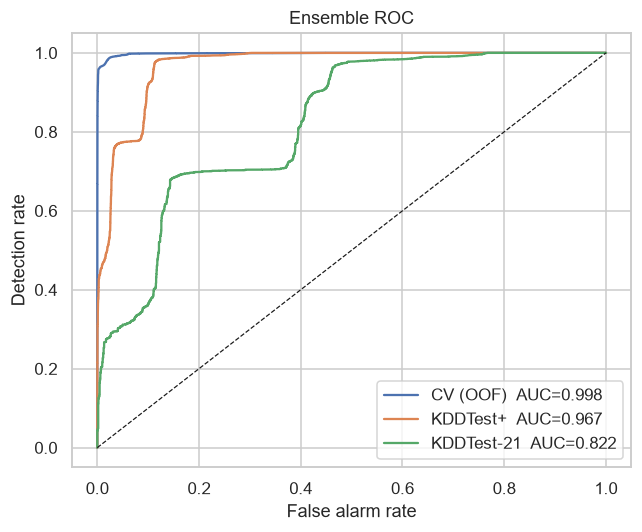

In [6]:
auc = pd.DataFrame({
    "leave-attack-out CV": {m: roc_auc_score(y, P[f"bin_oof_{m}"]) for m in ["xgb", "lgbm", "et", "ensemble"]},
    "KDDTest+": {**{m: roc_auc_score(yt, P[f"bin_test_{m}"]) for m in ["xgb", "lgbm", "et"]}, "ensemble": roc_auc_score(yt, P["bin_test"])},
    "KDDTest-21": {**{m: roc_auc_score(y21, P[f"bin_test21_{m}"]) for m in ["xgb", "lgbm", "et"]}, "ensemble": roc_auc_score(y21, P["bin_test21"])},
})
display(auc.round(4))
fig, ax = plt.subplots(figsize=(6, 5))
for name, yy, pp in [("CV (OOF)", y, P["bin_oof_ensemble"]), ("KDDTest+", yt, P["bin_test"]), ("KDDTest-21", y21, P["bin_test21"])]:
    fpr, tpr, _ = roc_curve(yy, pp); ax.plot(fpr, tpr, label=f"{name}  AUC={roc_auc_score(yy, pp):.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("False alarm rate"); ax.set_ylabel("Detection rate"); ax.legend()
ax.set_title("Ensemble ROC"); plt.tight_layout(); plt.savefig(FIG + "roc.png", bbox_inches="tight"); plt.show()

### 4.2 The decision threshold is the biggest lever

The test AUC is about 0.97, so the model *ranks* attacks well. At the default 0.5 cutoff, though, it misses about a third
of test attacks. Novel attacks get low but non-zero attack probabilities. The leave-attack-out OOF predictions show the
same behaviour, so the threshold is tuned there, by maximising F1 on attacks the model never saw. Test data is not used.

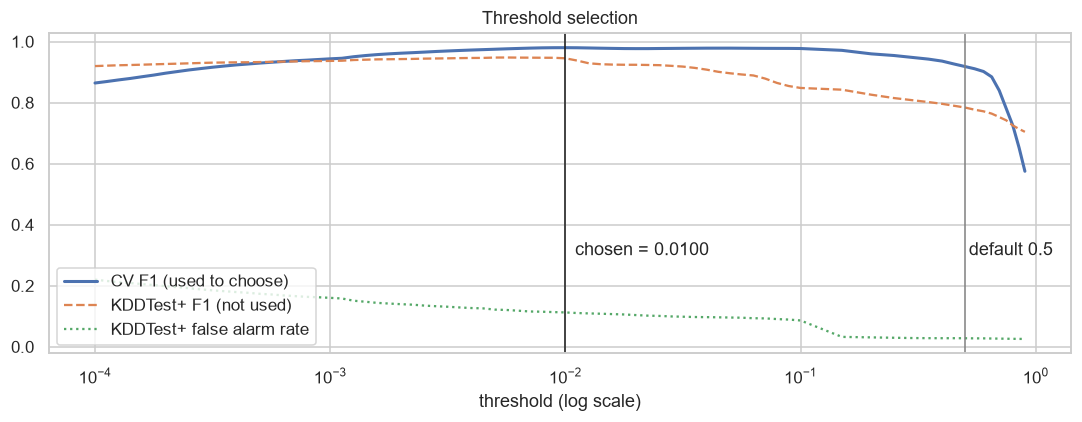

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
grid = P["bin_thr_grid"]
ax.semilogx(grid, P["bin_thr_f1"], label="CV F1 (used to choose)", lw=2)
ax.semilogx(grid, [f1_score(yt, P["bin_test"] >= t) for t in grid], label="KDDTest+ F1 (not used)", ls="--")
ax.semilogx(grid, [(P["bin_test"][yt == 0] >= t).mean() for t in grid], label="KDDTest+ false alarm rate", ls=":")
ax.axvline(THR, color="k", lw=1); ax.text(THR * 1.1, 0.3, f"chosen = {THR:.4f}")
ax.axvline(0.5, color="grey", lw=1); ax.text(0.52, 0.3, "default 0.5")
ax.set_xlabel("threshold (log scale)"); ax.legend(loc="lower left"); ax.set_title("Threshold selection")
plt.tight_layout(); plt.savefig(FIG + "threshold.png", bbox_inches="tight"); plt.show()

In [8]:
keys = ["cv_leave_attack_out@0.5", "cv_leave_attack_out@tuned", "test+@0.5", "test+@tuned", "test-21@0.5", "test-21@tuned"]
res = pd.DataFrame({k: M["binary"][k] for k in keys}).T
display(res.round(4))

,accuracy,precision,recall,f1,roc_auc,false_alarm_rate
cv_leave_attack_out@0.5,0.9296,0.9993,0.8494,0.9183,0.9984,0.0005
cv_leave_attack_out@tuned,0.9812,0.9743,0.9856,0.9799,0.9984,0.0226
test+@0.5,0.7934,0.9690,0.6581,0.7839,0.9674,0.0278
test+@tuned,0.9358,0.9196,0.9722,0.9452,0.9674,0.1123
test-21@0.5,0.6070,0.9516,0.5476,0.6952,0.8216,0.1255
test-21@tuned,0.8857,0.9035,0.9632,0.9324,0.8216,0.4638


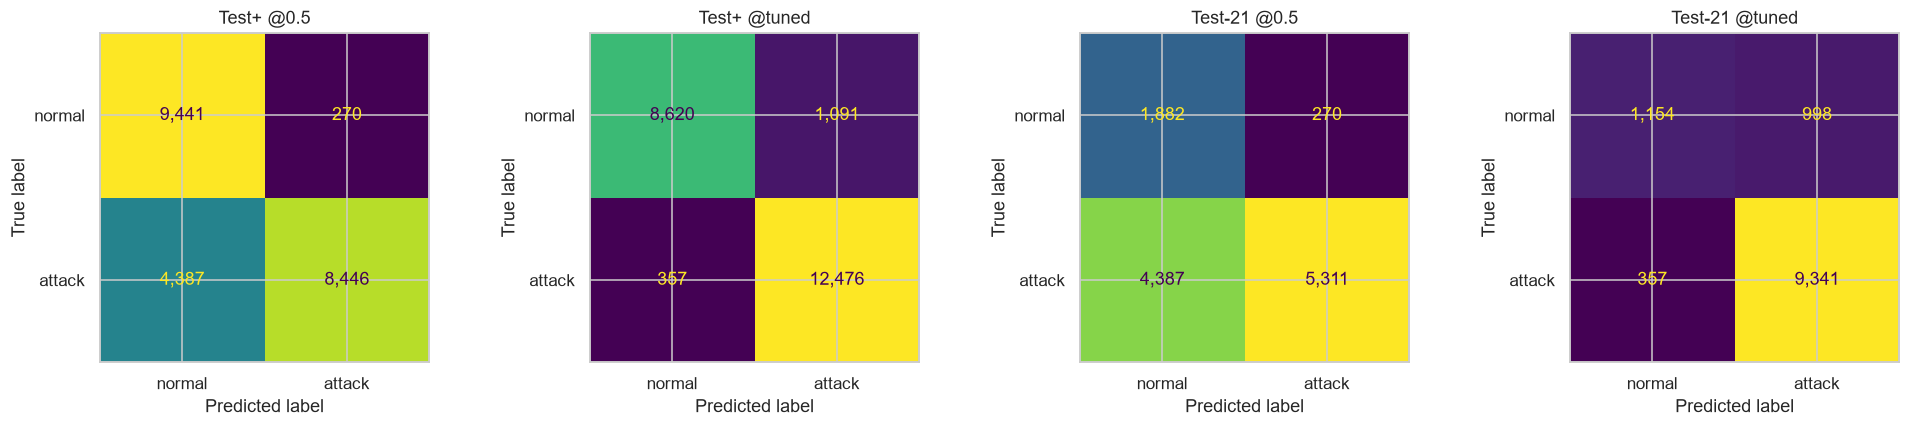

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, yy, pp, t) in zip(axes, [("Test+ @0.5", yt, P["bin_test"], .5), ("Test+ @tuned", yt, P["bin_test"], THR),
                                          ("Test-21 @0.5", y21, P["bin_test21"], .5), ("Test-21 @tuned", y21, P["bin_test21"], THR)]):
    ConfusionMatrixDisplay(confusion_matrix(yy, pp >= t), display_labels=["normal", "attack"]).plot(ax=ax, colorbar=False, values_format=",")
    ax.set_title(title)
plt.tight_layout(); plt.savefig(FIG + "binary_confusion.png", bbox_inches="tight"); plt.show()

### 4.3 Seen vs novel attack types
Where does the tuned threshold help? Detection rate per attack type on KDDTest+:

In [10]:
seen = set(train.label)
t = test.assign(p=P["bin_test"], det05=P["bin_test"] >= .5, det=P["bin_test"] >= THR, novel=~test.label.isin(seen))
grp = t[t.is_attack == 1].groupby("novel")[["det05", "det"]].mean().rename(index={False: "seen attack types", True: "novel attack types"})
grp.columns = ["detection @0.5", "detection @tuned"]; display(grp.round(4))
per = (t[t.is_attack == 1].groupby(["category", "label"])
       .agg(n=("p", "size"), novel=("novel", "first"), det_05=("det05", "mean"), det_tuned=("det", "mean"))
       .sort_values(["category", "n"], ascending=[True, False]))
per.round(3)

,detection @0.5,detection @tuned
novel,,
seen attack types,0.7739,0.9818
novel attack types,0.3779,0.9488


n  novel  det_05  det_tuned
category label                                          
DoS      neptune          4657  False   1.000      1.000
         apache2           737   True   0.719      0.997
         processtable      685   True   0.166      1.000
         smurf             665  False   1.000      1.000
         back              359  False   1.000      1.000
         mailbomb          293   True   0.000      0.956
         pod                41  False   0.951      1.000
         teardrop           12  False   1.000      1.000
         land                7  False   0.714      1.000
         udpstorm            2   True   1.000      1.000
         worm                2   True   0.000      0.000
Probe    mscan             996   True   0.446      1.000
         satan             735  False   1.000      1.000
         saint             319   True   0.987      1.000
         portsweep         157  False   1.000      1.000
         ipsweep           141  False   1.000      1.000
         nmap               73  False   1.000      1.000
R2L      guess_passwd     1231  False   0.000      0.903
         warezmaster       944  False   0.188      0.959
         snmpguess         331   True   0.000      1.000
         snmpgetattack     178   True   0.000      0.062
         httptunnel        133   True   0.015      0.992
         multihop           18  False   0.167      0.944
         named              17   True   0.176      1.000
         sendmail           14   True   0.000      0.857
         xlock               9   True   0.000      0.778
         xsnoop              4   True   0.250      1.000
         ftp_write           3  False   0.333      1.000
         phf                 2  False   0.500      0.500
         imap                1  False   0.000      1.000
U2R      buffer_overflow    20  False   0.250      1.000
         ps                 15   True   0.133      0.867
         rootkit            13  False   0.000      0.615
         xterm              13   True   0.308      0.923
         loadmodule          2  False   0.500      1.000
         perl                2  False   0.000      1.000
         sqlattack           2   True   0.000      1.000

## 5. Multi-class detector: Normal / DoS / Probe / R2L / U2R

Same engineered features. The class model is a LightGBM + ExtraTrees ensemble with **sqrt-balanced sample weights**
(LightGBM) and `balanced_subsample` (ExtraTrees), because R2L is 0.8% and U2R 0.04% of training.

**Two-stage decision (chosen on leave-attack-out CV):**
1. The binary detector (§4, tuned threshold) decides *normal vs attack*.
2. For rows flagged as attacks, the class model picks the most likely of the 4 attack categories.

Plain 5-class argmax almost never predicts R2L. Most test R2L rows are novel attack types that look closer to normal
than to the R2L types seen in training. The binary stage catches them as "attack". The class model then only has to
choose *which kind* of attack, and it does much better at that.

I also tried per-class probability weights tuned for macro-F1 on CV. They suppressed R2L completely in CV, because every
CV R2L row is an unseen type, so that approach was dropped.

In [11]:
from src.model import hierarchical_decision
keys = ["cv_leave_attack_out@argmax", "cv_leave_attack_out@hierarchical", "test+@argmax", "test+@hierarchical", "test-21@argmax", "test-21@hierarchical"]
display(pd.DataFrame({k: M["multiclass"][k] for k in keys}).T.round(4))

,accuracy,macro_f1,weighted_f1,recall_Normal,recall_DoS,recall_Probe,recall_R2L,recall_U2R
cv_leave_attack_out@argmax,0.6180,0.3434,0.4886,0.9997,0.0044,0.8848,0.0000,0.2692
cv_leave_attack_out@hierarchical,0.6460,0.4063,0.6143,0.9774,0.0803,0.9737,0.4864,0.6538
test+@argmax,0.7578,0.5734,0.7215,0.9725,0.7827,0.6448,0.0780,0.2239
test+@hierarchical,0.8252,0.6731,0.8304,0.8877,0.8694,0.9232,0.4208,0.7164
test-21@argmax,0.5397,0.4771,0.5358,0.8759,0.6280,0.6420,0.0780,0.2239
test-21@hierarchical,0.6757,0.6005,0.6747,0.5362,0.7769,0.9226,0.4208,0.7164


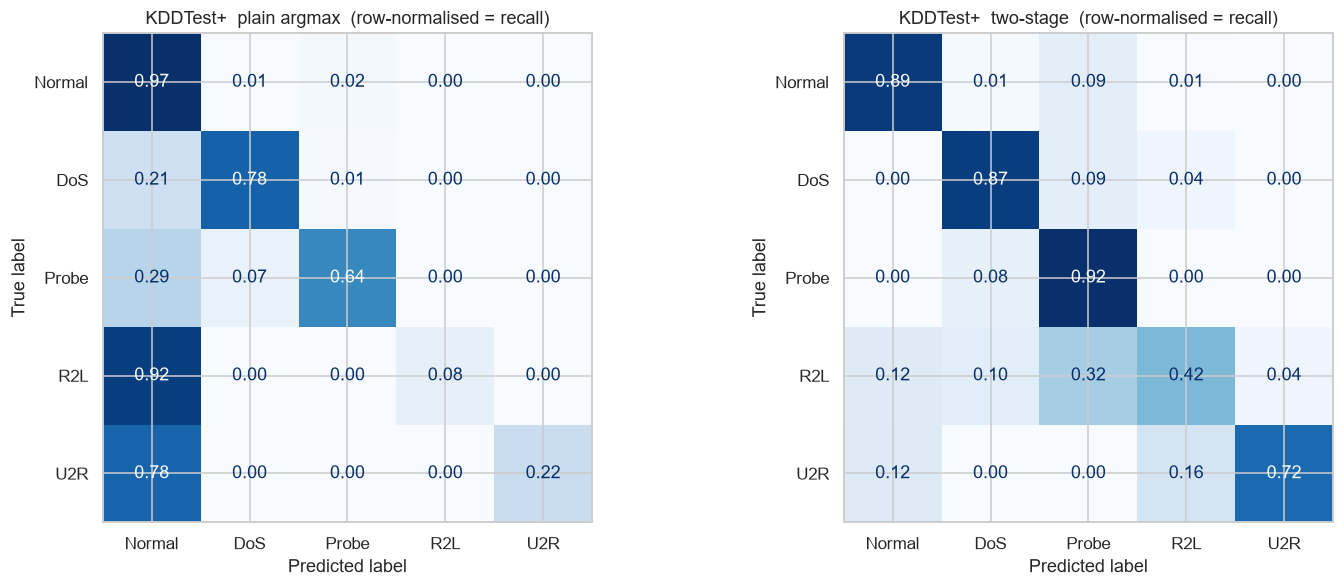

              precision    recall  f1-score   support

      Normal     0.9602    0.8877    0.9225      9711
         DoS     0.9143    0.8694    0.8913      7460
       Probe     0.4746    0.9232    0.6269      2421
         R2L     0.7688    0.4208    0.5439      2885
         U2R     0.2595    0.7164    0.3810        67

    accuracy                         0.8252     22544
   macro avg     0.6755    0.7635    0.6731     22544
weighted avg     0.8663    0.8252    0.8304     22544



In [12]:
cmap = {c: i for i, c in enumerate(CLASSES)}
ytc = test.category.map(cmap).values
pred_t = hierarchical_decision(P["bin_test"], P["mc_test"], THR)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, pr) in zip(axes, [("KDDTest+  plain argmax", P["mc_test"].argmax(1)), ("KDDTest+  two-stage", pred_t)]):
    ConfusionMatrixDisplay(confusion_matrix(ytc, pr, normalize="true"), display_labels=CLASSES).plot(ax=ax, colorbar=False, values_format=".2f", cmap="Blues")
    ax.set_title(title + "  (row-normalised = recall)")
plt.tight_layout(); plt.savefig(FIG + "multiclass_confusion.png", bbox_inches="tight"); plt.show()
print(classification_report(ytc, pred_t, target_names=CLASSES, digits=4))

## 6. Using the saved models

In [13]:
sample = test.sample(8, random_state=1)
out = sample[["protocol_type", "service", "flag", "src_bytes", "label", "category"]].copy()
out["P(attack)"] = bin_det.predict_proba(sample).round(4)
out["binary_pred"] = np.where(bin_det.predict(sample) == 1, "attack", "normal")
out["category_pred"] = [CLASSES[i] for i in mc_det.predict(sample)]
out

,protocol_type,service,flag,src_bytes,label,category,P(attack),binary_pred,category_pred
13003,tcp,telnet,SF,126,guess_passwd,R2L,0.0258,attack,Probe
8908,tcp,private,REJ,0,neptune,DoS,1.0000,attack,DoS
11599,tcp,http,SF,320,normal,Normal,0.0000,normal,Normal
20226,tcp,http,SF,220,normal,Normal,0.0000,normal,Normal
11643,tcp,pop_3,SF,30,guess_passwd,R2L,0.0101,attack,Probe
12044,tcp,ftp_data,SF,12,warezmaster,R2L,0.3555,attack,R2L
12470,tcp,private,S0,0,neptune,DoS,1.0000,attack,DoS
10324,tcp,other,REJ,0,saint,Probe,0.9700,attack,Probe


## 7. Summary: all results in one table

Every model scored on both held-out test sets with the same metrics.
- **Precision / Recall / F1**: for the attack class in binary rows, macro-averaged over the 5 classes in 5-class rows.
- **Detection rate**: share of attacks flagged as any attack.
- **False alarm rate**: share of normal traffic flagged as an attack.

The baseline (XGBoost on the raw 41 features, 0.5 cutoff) is retrained here, which takes about 30 s, so every row is scored the same way.

In [14]:
from sklearn.metrics import precision_score, recall_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from src.features import make_raw_preprocessor
from src.model import hierarchical_decision

cmap = {c: i for i, c in enumerate(CLASSES)}
SETS = {"KDDTest+": (test, "test"), "KDDTest-21": (test21, "test21")}

baseline = Pipeline([("pre", make_raw_preprocessor()),
                     ("clf", XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=8, n_jobs=-1,
                                           random_state=0, verbosity=0))]).fit(train, y)
base_p = {key: baseline.predict_proba(df)[:, 1] for df, key in SETS.values()}

def score(df, pred, p_attack=None, five_class=False):
    yb = df.is_attack.values
    flagged = (pred != 0)
    if five_class:
        yc, avg = df.category.map(cmap).values, dict(average="macro", zero_division=0)
        prf = (precision_score(yc, pred, **avg), recall_score(yc, pred, **avg), f1_score(yc, pred, **avg))
        acc, auc = accuracy_score(yc, pred), np.nan
    else:
        prf = (precision_score(yb, pred), recall_score(yb, pred), f1_score(yb, pred))
        acc, auc = accuracy_score(yb, pred), roc_auc_score(yb, p_attack)
    return {"Accuracy": acc, "Precision": prf[0], "Recall": prf[1], "F1": prf[2],
            "Detection rate": flagged[yb == 1].mean(), "False alarm rate": flagged[yb == 0].mean(), "ROC-AUC": auc}

MODELS = {
    ("Binary", "Baseline: XGBoost, raw features, 0.5 cutoff"):
        lambda df, k: score(df, (base_p[k] >= 0.5).astype(int), base_p[k]),
    ("Binary", "Ensemble + engineered features, 0.5 cutoff"):
        lambda df, k: score(df, (P[f"bin_{k}"] >= 0.5).astype(int), P[f"bin_{k}"]),
    ("Binary", f"★ FINAL: ensemble + tuned threshold ({THR:.2f})"):
        lambda df, k: score(df, (P[f"bin_{k}"] >= THR).astype(int), P[f"bin_{k}"]),
    ("5-class", "Plain multi-class (argmax)"):
        lambda df, k: score(df, P[f"mc_{k}"].argmax(1), five_class=True),
    ("5-class", "★ FINAL: two-stage (binary → category)"):
        lambda df, k: score(df, hierarchical_decision(P[f"bin_{k}"], P[f"mc_{k}"], THR), five_class=True),
}

results = pd.DataFrame({
    idx: {(set_name, metric): v for set_name, (df, k) in SETS.items() for metric, v in fn(df, k).items()}
    for idx, fn in MODELS.items()
}).T
results.index.names = ["Task", "Model"]
results.to_csv("../reports/final_results.csv")

final_style = "background-color:#d4edda; color:#14532d; font-weight:bold"
(results.style
    .format("{:.1%}", na_rep="–")
    .apply(lambda row: [final_style if "FINAL" in row.name[1] else "" for _ in row], axis=1)
    .set_caption("All scores on held-out test data (never used for tuning). Also saved to reports/final_results.csv")
    .set_table_styles([{"selector": "caption", "props": "caption-side:bottom; text-align:left; font-size:0.85em"},
                       {"selector": "th.col_heading", "props": "text-align:center"}]))

**What made the difference**
1. **Leave-attack-type-out validation.** It's the only CV that reflects the test set, and it made threshold tuning
   possible without touching test data.
2. **Decision-rule tuning.** The biggest gain. It turns good ranking (AUC ~0.97) into good detection, including novel attacks.
3. **Two-stage 5-class model.** It reuses the binary detector, so novel R2L/U2R attacks are still caught and categorised.
4. **Feature engineering + a diverse regularised ensemble.** Consistent gains under realistic validation.

**Honest limitations**
- The tuned threshold trades a higher false-alarm rate on normal traffic for much higher detection: about 11% on
  KDDTest+, and much higher on KDDTest-21, whose normal rows were picked for being hard. If false alarms are expensive,
  pick a higher threshold from the curve in §4.2.
- A few test attack types are barely separable from normal traffic with these 41 features (see the per-attack table in §4.3).
- U2R has only 52 training rows (67 in test). Its per-class scores are unstable and should be read with care.
- NSL-KDD is synthetic 1998 traffic. Validate on a modern dataset (CIC-IDS2017, UNSW-NB15) before drawing conclusions
  about real networks.